## Oresund

In [1]:
%load_ext autoreload
%autoreload 2

In [10]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements, error_mshred
from helper import plot_shred_reconstruction_better, plot_shred_reconstruction_best, plot_shred_reconstruction_multi

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load Data and Measurement

In [3]:
# OPEN FOLDERS
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/mesh_EMOD.mesh"
obs_fldr  = "datasets/observations/"
msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

ds = dfs.read(time = slice("2019-01-01", "2023-10-31"))

# sensor coverage
alllist = get_wl_point_obs()

# For sparse data simulation
#hf = ["Drogden", "Klagshamn", "Dragor", "Barseback"]
# availabilities 97-50-98-50
#alllist = [s for s in alllist if s.name in hf]

# Extract the values and convert to torch tensors

measurements = extract_water_level_measurements(alllist, ds_time=ds.time, obs_fldr=obs_fldr)
measurements = torch.as_tensor(measurements, dtype=torch.float32)
print("IN:\nMeasurements shape:", measurements.shape)

# Build a single mask for nodes that are valid in all output fields
surface = ds["Surface elevation"].values
u_velocity = ds["U velocity"].values
v_velocity = ds["V velocity"].values
valid_nodes = np.isfinite(surface).all(axis=0) & np.isfinite(u_velocity).all(axis=0) & np.isfinite(v_velocity).all(axis=0)

# outputs
H = torch.from_numpy(surface[:, valid_nodes].astype(np.float32, copy=False))
U = torch.from_numpy(u_velocity[:, valid_nodes].astype(np.float32, copy=False))
V = torch.from_numpy(v_velocity[:, valid_nodes].astype(np.float32, copy=False))

# print the shape of the arrays
print("OUT:\nH shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)

# free memory
del surface, u_velocity, v_velocity, valid_nodes, dfs, alllist

IN:
Measurements shape: torch.Size([84720, 12])
OUT:
H shape: torch.Size([84720, 3320])
U shape: torch.Size([84720, 3320])
V shape: torch.Size([84720, 3320])


In [4]:
ERRORS = []

# DataManager
LAGS = 24

TRAIN_SIZE = 0.70        # percentage of data used for training 
VAL_SIZE = 0.15          # percentage of data used for validation
TEST_SIZE = 0.15         # percentage of data used for testing

COMPRESS_H = 15         # modes kept for H (surface elevation)
COMPRESS_U = 100         # modes kept for U (U velocity)
COMPRESS_V = 100         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 3               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64,96]     # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.3.G): Masking x2 channels + MHSA learned

In [5]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 296298

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 12]) -> torch.Size([59303, 215])
Val:	 torch.Size([12709, 24, 12]) -> torch.Size([12709, 215])
Test:	 torch.Size([12708, 24, 12]) -> torch.Size([12708, 215])

Input shape for the model: 12
Output shape for the model: 215


In [6]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

del train_dataset, val_dataset, train_errors, valid_errors, model_args

Starting training...


Training:  86%|████████▋ | 173/200 [55:19<08:38, 19.19s/it, Train Loss=0.00327, Val Loss=0.00369, Patience=39, Best Val Loss=0.00365, LR=2.06e-05]

Early stopping at epoch 174
Training completed with best validation loss: 0.0037


In [7]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

del test_dataset, engine, mshred

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/ORESUND_reconstruction_grid.png


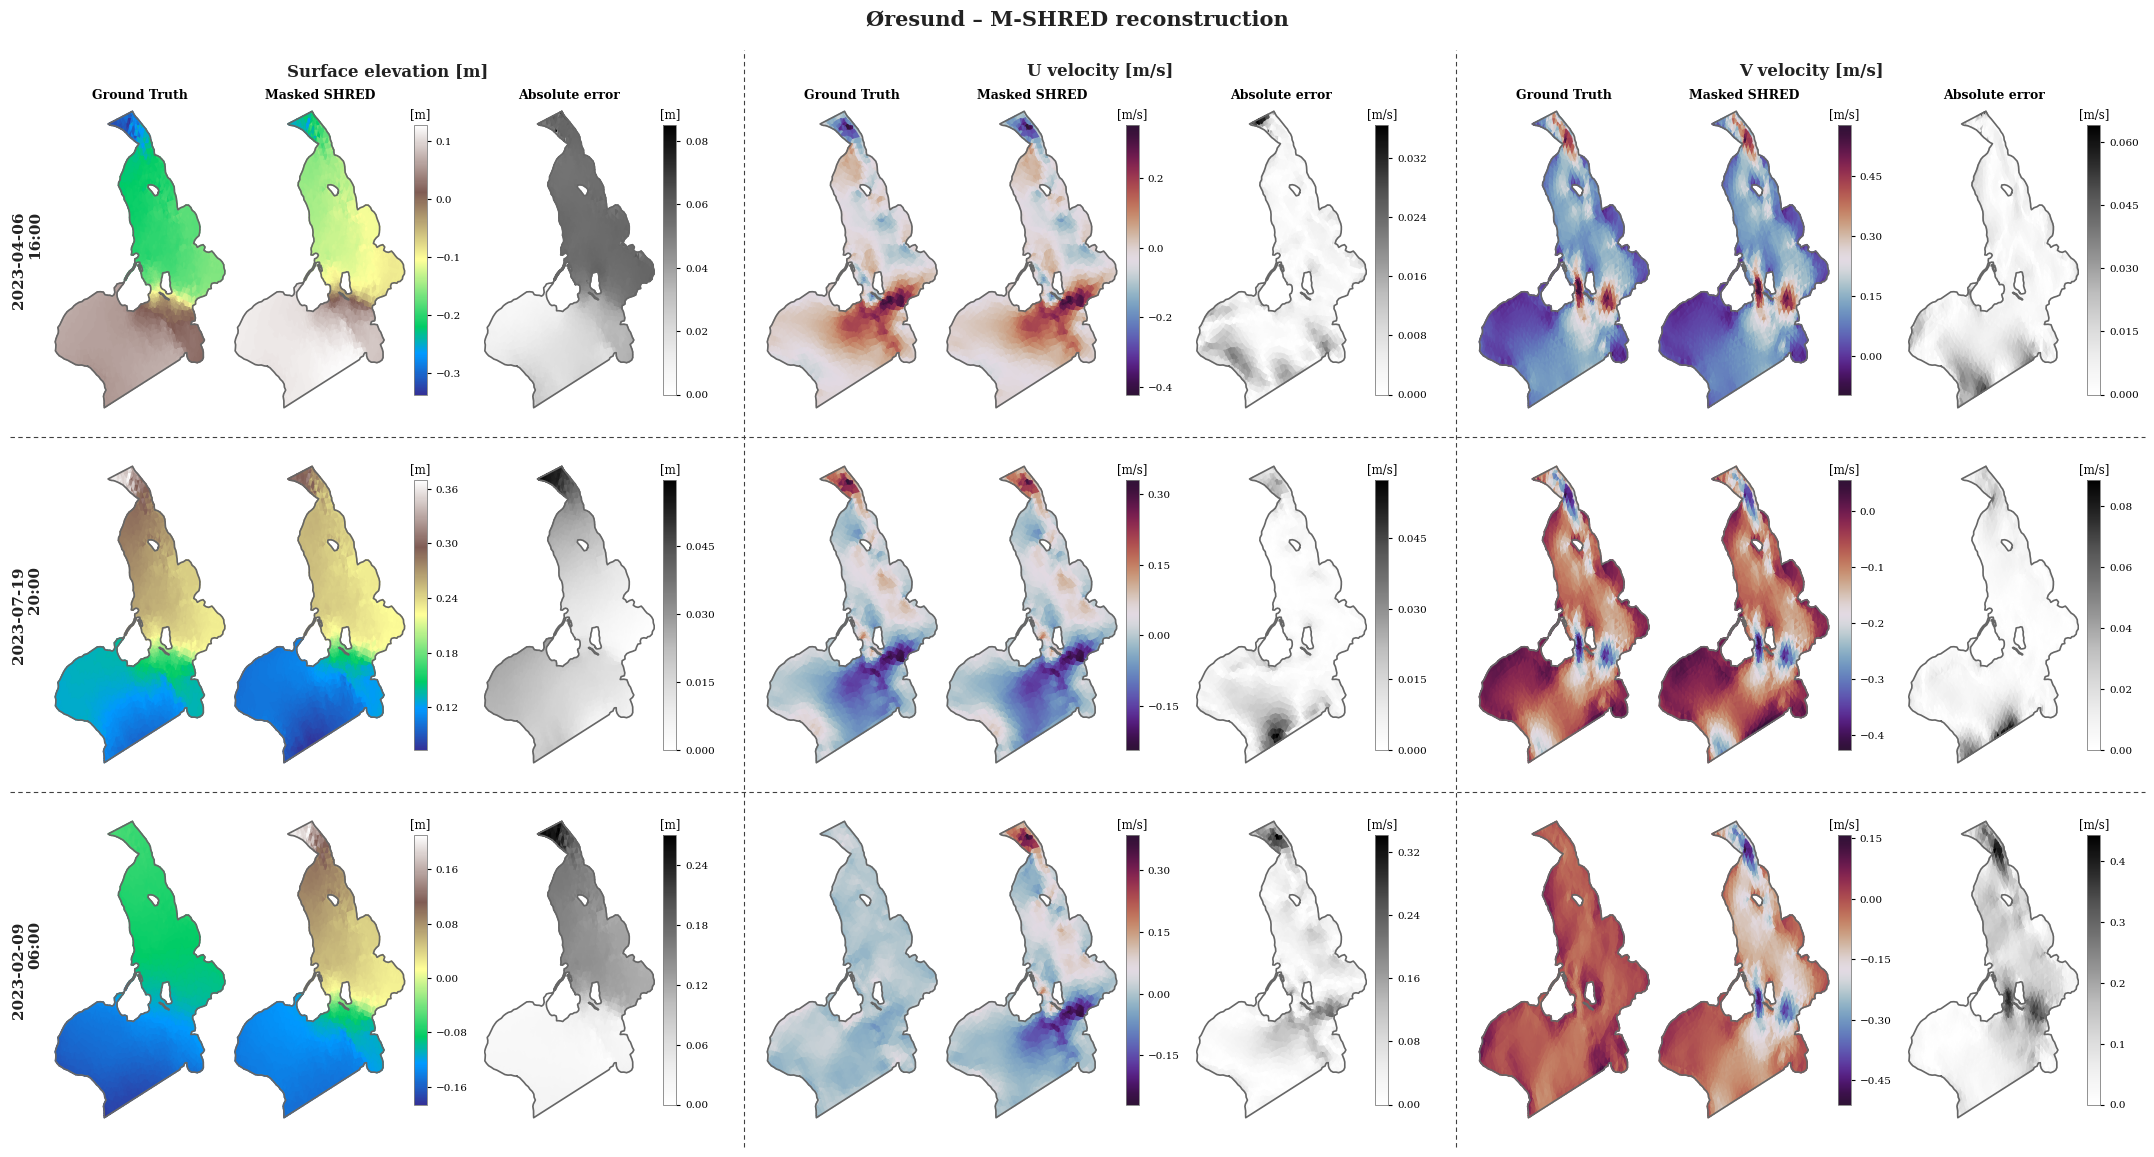

In [13]:
plot_shred_reconstruction_multi(
    test_reconstruction, ds, geom,
    time_idxs=(-10000, -5000, 0),
    title="ORESUND_reconstruction_grid",
    fig_title="Øresund – M-SHRED reconstruction",
)